multi-scale octaves, random jitter/shifts each step, gradient normalization, and optionally a light blur or total-variation penalty.

In [2]:
import torch, torchvision
from lucent.modelzoo import inceptionv1

In [34]:
import torchvision.transforms as T
from datasets import load_dataset
from itertools import islice
import matplotlib.pyplot as plt

ds = load_dataset("uoft-cs/cifar10", split="train", streaming=True)
names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
exs = list(islice(ds.shuffle(seed=3214, buffer_size=500), 10))

mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
std  = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
tf = T.Compose([T.Resize(320), T.ToTensor(), T.Normalize(mean, std)])

for x in exs:
    x["img"] = tf(x["img"])

In [7]:
m = torchvision.models.resnet50(weights="DEFAULT").eval()
feats = {}
# m.layer3.register_forward_hook(lambda _, __, o: feats.update(out=o))
for name, _ in m.named_modules():
    print(name)


conv1
bn1
relu
maxpool
layer1
layer1.0
layer1.0.conv1
layer1.0.bn1
layer1.0.conv2
layer1.0.bn2
layer1.0.conv3
layer1.0.bn3
layer1.0.relu
layer1.0.downsample
layer1.0.downsample.0
layer1.0.downsample.1
layer1.1
layer1.1.conv1
layer1.1.bn1
layer1.1.conv2
layer1.1.bn2
layer1.1.conv3
layer1.1.bn3
layer1.1.relu
layer1.2
layer1.2.conv1
layer1.2.bn1
layer1.2.conv2
layer1.2.bn2
layer1.2.conv3
layer1.2.bn3
layer1.2.relu
layer2
layer2.0
layer2.0.conv1
layer2.0.bn1
layer2.0.conv2
layer2.0.bn2
layer2.0.conv3
layer2.0.bn3
layer2.0.relu
layer2.0.downsample
layer2.0.downsample.0
layer2.0.downsample.1
layer2.1
layer2.1.conv1
layer2.1.bn1
layer2.1.conv2
layer2.1.bn2
layer2.1.conv3
layer2.1.bn3
layer2.1.relu
layer2.2
layer2.2.conv1
layer2.2.bn1
layer2.2.conv2
layer2.2.bn2
layer2.2.conv3
layer2.2.bn3
layer2.2.relu
layer2.3
layer2.3.conv1
layer2.3.bn1
layer2.3.conv2
layer2.3.bn2
layer2.3.conv3
layer2.3.bn3
layer2.3.relu
layer3
layer3.0
layer3.0.conv1
layer3.0.bn1
layer3.0.conv2
layer3.0.bn2
layer3.0.conv

In [46]:
m = torchvision.models.googlenet(weights="DEFAULT").eval()
feats = {}
# m.inception3a.register_forward_hook(lambda _, __, o: feats.update(out=o)) # swirls, textures, edges
# m.inception3b.register_forward_hook(lambda _, __, o: feats.update(out=o)) # swirls, textures, edges

# m.inception4a.register_forward_hook(lambda _, __, o: feats.update(out=o)) # patterns, eyes, fur
# m.inception4b.register_forward_hook(lambda _, __, o: feats.update(out=o))
# m.inception4c.register_forward_hook(lambda _, __, o: feats.update(out=o))
m.inception4d.register_forward_hook(lambda _, __, o: feats.update(out=o)) # dog faces, animal parts (the classic look)
m.inception4e.register_forward_hook(lambda _, __, o: feats.update(out=o))

# m.inception5a.register_forward_hook(lambda _, __, o: feats.update(out=o)) # whole objects, but blurrier since resolution is low
# m.inception5b.register_forward_hook(lambda _, __, o: feats.update(out=o))
for name, _ in m.named_modules():
    print(name)


conv1
conv1.conv
conv1.bn
maxpool1
conv2
conv2.conv
conv2.bn
conv3
conv3.conv
conv3.bn
maxpool2
inception3a
inception3a.branch1
inception3a.branch1.conv
inception3a.branch1.bn
inception3a.branch2
inception3a.branch2.0
inception3a.branch2.0.conv
inception3a.branch2.0.bn
inception3a.branch2.1
inception3a.branch2.1.conv
inception3a.branch2.1.bn
inception3a.branch3
inception3a.branch3.0
inception3a.branch3.0.conv
inception3a.branch3.0.bn
inception3a.branch3.1
inception3a.branch3.1.conv
inception3a.branch3.1.bn
inception3a.branch4
inception3a.branch4.0
inception3a.branch4.1
inception3a.branch4.1.conv
inception3a.branch4.1.bn
inception3b
inception3b.branch1
inception3b.branch1.conv
inception3b.branch1.bn
inception3b.branch2
inception3b.branch2.0
inception3b.branch2.0.conv
inception3b.branch2.0.bn
inception3b.branch2.1
inception3b.branch2.1.conv
inception3b.branch2.1.bn
inception3b.branch3
inception3b.branch3.0
inception3b.branch3.0.conv
inception3b.branch3.0.bn
inception3b.branch3.1
incepti

3a/3b: swirls, textures, edges
4a–4c: patterns, eyes, fur
4d/4e: dog faces, animal parts (the classic look)
5a/5b: whole objects, but blurrier since resolution is low

In [ ]:
m = inceptionv1(pretrained=True).eval()
feats = {}

# m.mixed4c.register_forward_hook(lambda _, __, o: feats.update(out=o))
for name, _ in m.named_modules():
    print(name)

Downloading: "https://github.com/ProGamerGov/pytorch-old-tensorflow-models/raw/master/inception5h.pth" to /root/.cache/torch/hub/checkpoints/inception5h.pth


100%|██████████| 27.0M/27.0M [00:00<00:00, 425MB/s]


conv2d0_pre_relu_conv
conv2d1_pre_relu_conv
conv2d2_pre_relu_conv
mixed3a_1x1_pre_relu_conv
mixed3a_3x3_bottleneck_pre_relu_conv
mixed3a_5x5_bottleneck_pre_relu_conv
mixed3a_pool_reduce_pre_relu_conv
mixed3a_3x3_pre_relu_conv
mixed3a_5x5_pre_relu_conv
mixed3b_1x1_pre_relu_conv
mixed3b_3x3_bottleneck_pre_relu_conv
mixed3b_5x5_bottleneck_pre_relu_conv
mixed3b_pool_reduce_pre_relu_conv
mixed3b_3x3_pre_relu_conv
mixed3b_5x5_pre_relu_conv
mixed4a_1x1_pre_relu_conv
mixed4a_3x3_bottleneck_pre_relu_conv
mixed4a_5x5_bottleneck_pre_relu_conv
mixed4a_pool_reduce_pre_relu_conv
mixed4a_3x3_pre_relu_conv
mixed4a_5x5_pre_relu_conv
mixed4b_1x1_pre_relu_conv
mixed4b_3x3_bottleneck_pre_relu_conv
mixed4b_5x5_bottleneck_pre_relu_conv
mixed4b_pool_reduce_pre_relu_conv
mixed4b_3x3_pre_relu_conv
mixed4b_5x5_pre_relu_conv
mixed4c_1x1_pre_relu_conv
mixed4c_3x3_bottleneck_pre_relu_conv
mixed4c_5x5_bottleneck_pre_relu_conv
mixed4c_pool_reduce_pre_relu_conv
mixed4c_3x3_pre_relu_conv
mixed4c_5x5_pre_relu_conv
mix

### Bare Minimum Example

In [39]:
def show(img):
    img = (img.detach().cpu() + 1) / 2          # [-1, 1] → [0, 1]
    img = img.clamp(0, 1).permute(1, 2, 0)      # (C, H, W) → (H, W, C)
    plt.figure(figsize=(4, 4)) 
    plt.imshow(img)
    plt.axis("off")
    plt.show()

dog


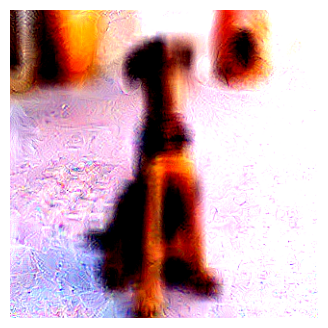

[W1004 09:32:05.340417250 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.350993710 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.363618238 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.374679833 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.385112860 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.393372451 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.395305289 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.399676934 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.401664521 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1004 09:32:05.407642527 NNPACK.cpp:56] Could not initialize NNPACK! Reason: Unsupported hardware.


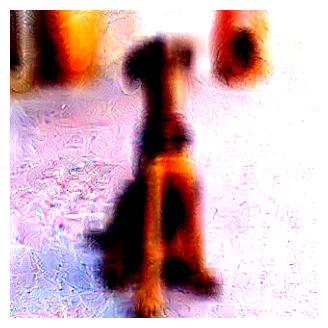

In [51]:
row = exs[3]
img = row["img"]
print(names[row["label"]])

show(img)
img = img.unsqueeze(0)
for _ in range(20):
    img = img.detach().requires_grad_()
    m(img)
    loss = feats["out"].norm()
    loss.backward()

    with torch.no_grad():
        g = img.grad / (img.grad.abs().mean() + 1e-8)
        img.data += 0.01 * g
    
    img.grad.zero_()

show(img[0])